### What we are working from

Notebook 04 re-scores the 65 diagnosis patients with the egg detector trained in
notebook 03, then asks again whether confidence-based deferral beats random
deferral. Two sources feed it: `detector.pt`, attached from notebook 03's
committed output, and the original diagnosis dataset, downloaded fresh from
Zenodo and checksum-verified. The listing below confirms what is attached
before anything runs.

In [1]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        p = os.path.join(root, f)
        print(f"{os.path.getsize(p)/1e6:10.1f} MB  {p}")

       0.0 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/fig_patient_scores.png
       0.8 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/patient_scores.npz
       2.7 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/fig_hard_cases.png
       0.4 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__results__.html
       0.1 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/fig_risk_coverage.png
       2.5 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__notebook__.ipynb
       0.0 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__output__.json
       0.0 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/custom.css
       0.0 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__results___files/__results___15_0.png
       1.7 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__results___files/__results___23_0.png
       0.1 MB  /kaggle/input/notebooks/oglorypaul/04-rescore/__results___files/__results___21_1.png
       0.9 MB  /kaggle/input/notebooks/oglorypaul/03-detector/__re

## 1 · Setup

Libraries, paths, and a scratch folder for the 12.5 GB dataset archive. The
archive is kept outside `/kaggle/working` on purpose: anything in the working
directory is saved with the notebook, and this output should hold only the
scores, small enough to attach quickly later.

In [2]:
import os, io, time, random, shutil, hashlib, pathlib, threading, zipfile, collections
import numpy as np, pandas as pd, requests, torch, torch.nn as nn, torchvision
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

WORK = pathlib.Path("/kaggle/working")
DET  = "/kaggle/input/notebooks/oglorypaul/03-detector/detector.pt"
TRN  = "/kaggle/input/notebooks/oglorypaul/03-detector/trainset"
assert os.path.exists(DET), "detector.pt not attached"

def pick_scratch():
    for cand in ("/kaggle/temp", "/tmp"):
        p = pathlib.Path(cand)
        try:
            p.mkdir(parents=True, exist_ok=True)
            (p / ".w").write_text("x"); (p / ".w").unlink()
            return p
        except Exception:
            pass
    raise RuntimeError("no scratch dir")

SCRATCH  = pick_scratch()
ZIP_PATH = SCRATCH / "diagnosis_test_dataset.zip"

print("GPU      :", torch.cuda.get_device_name(0))
print("scratch  :", SCRATCH, f"· {shutil.disk_usage(SCRATCH).free/1e9:.1f} GB free")
print("working  :", f"{shutil.disk_usage(WORK).free/1e9:.1f} GB free")

GPU      : Tesla T4
scratch  : /kaggle/temp · 1146.0 GB free
working  : 20.9 GB free


## 2 · The diagnosis dataset

The 65 patients' images are downloaded from Zenodo (record 6467268) over 16
parallel connections, each retrying with backoff when the server throttles.
The finished file is checked against the MD5 checksum Zenodo publishes, so a
corrupted download stops the notebook here rather than silently changing the
results.

In [3]:
rec  = requests.get("https://zenodo.org/api/records/6467268", timeout=60).json()
meta = next(f for f in rec["files"] if f["key"] == "diagnosis_test_dataset.zip")
SRC_URL, TOTAL = meta["links"]["self"], meta["size"]
MD5_PUB = meta["checksum"].split(":")[1]

N_CONN, RETRIES, CHUNK = 16, 8, 4 * 1024 * 1024
with open(ZIP_PATH, "wb") as f:
    f.truncate(TOTAL)

bar, lock = tqdm(total=TOTAL, unit="B", unit_scale=True, unit_divisor=1024, desc="download"), threading.Lock()

def fetch_range(start, end):
    for attempt in range(RETRIES):
        pos = start
        try:
            with requests.get(SRC_URL, headers={"Range": f"bytes={pos}-{end}"},
                              stream=True, timeout=(30, 300)) as r:
                if r.status_code != 206:
                    raise RuntimeError(f"expected 206, got {r.status_code}")
                with open(ZIP_PATH, "r+b") as f:
                    f.seek(pos)
                    for chunk in r.iter_content(chunk_size=CHUNK):
                        if chunk:
                            f.write(chunk); pos += len(chunk)
                            with lock: bar.update(len(chunk))
            if pos - 1 == end:
                return True, None
            raise RuntimeError("short segment")
        except Exception as e:
            with lock: bar.update(-(pos - start))
            time.sleep(min(2 ** attempt, 30) + random.random() * 2)
            err = f"{type(e).__name__}: {e}"

    return False, err

seg    = TOTAL // N_CONN
ranges = [(i * seg, TOTAL - 1 if i == N_CONN - 1 else (i + 1) * seg - 1) for i in range(N_CONN)]
with ThreadPoolExecutor(N_CONN) as ex:
    for fut in as_completed([ex.submit(fetch_range, s, e) for s, e in ranges]):
        ok, err = fut.result()
        assert ok, f"segment failed: {err}"
bar.close()

md5 = hashlib.md5()
with open(ZIP_PATH, "rb") as f:
    for b in iter(lambda: f.read(64 * 1024 * 1024), b""):
        md5.update(b)
assert md5.hexdigest() == MD5_PUB, "checksum mismatch: file is corrupt"
print(f"verified · {TOTAL/1e9:.2f} GB · md5 {MD5_PUB}")

download:   0%|          | 0.00/11.7G [00:00<?, ?B/s]

verified · 12.52 GB · md5 76c20a6c5f566c2f141b6dd274ea4d74


### Structure and labels

The same checks as notebook 02: exactly 65 patients, exactly 117 images each,
and a label file whose IDs match the image folders one-for-one. Labels are
sorted by sample ID, and every array indexed by patient from here on follows
that order.

In [4]:
zf    = zipfile.ZipFile(ZIP_PATH)
names = zf.namelist()
IMGS  = [n for n in names if n.lower().endswith(".jpeg")]
CSVS  = [n for n in names if n.lower().endswith(".csv")]

per = collections.Counter(pathlib.PurePosixPath(n).parent.name for n in IMGS)
assert len(per) == 65 and set(per.values()) == {117}, "unexpected structure"

labels  = pd.read_csv(io.BytesIO(zf.read(CSVS[0]))).sort_values("sample_id").reset_index(drop=True)
SAMPLES = [str(s) for s in labels.sample_id]
assert set(SAMPLES) == set(per), "label IDs don't match image folders"

y    = labels.diagnosis.values.astype(int)
eggs = labels.egg_count.values.astype(int)
print(f"65 patients · 7,605 images · {y.sum()} positive / {(1-y).sum()} negative")

65 patients · 7,605 images · 32 positive / 33 negative


## 3 · The detector

The ResNet18 from notebook 03 is rebuilt with the same single-output head and
its trained weights loaded. Before it touches a patient, it is checked on 600
of its own training tiles: egg tiles should score near 1 and empty tiles near
0. If they don't, the weights failed to load, and it is caught here rather
than discovered in the results.

In [5]:
DEV  = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

model = torchvision.models.resnet18(weights=None)
model.fc = nn.Linear(512, 1)
model.load_state_dict(torch.load(DET, map_location="cpu"))
model = model.to(DEV).eval()

@torch.no_grad()
def score(tiles):                       # uint8 array (N, 256, 256, 3)
    out = []
    for i in range(0, len(tiles), 256):
        t = torch.from_numpy(np.ascontiguousarray(tiles[i:i+256])).to(DEV)
        t = (t.permute(0, 3, 1, 2).float().div_(255) - MEAN) / STD
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(torch.sigmoid(model(t).squeeze(1)).float().cpu().numpy())
    return np.concatenate(out)

Xtr = np.load(f"{TRN}/X.npy", mmap_mode="r")
ytr = np.load(f"{TRN}/y.npy")
rng = np.random.default_rng(0)
pos = np.sort(rng.choice(np.where(ytr == 1)[0], 300, replace=False))
neg = np.sort(rng.choice(np.where(ytr == 0)[0], 300, replace=False))
print(f"mean score · egg tiles {score(Xtr[pos]).mean():.3f} · empty tiles {score(Xtr[neg]).mean():.3f}")

mean score · egg tiles 0.844 · empty tiles 0.043


## 4 · Scoring the 65 patients

Every frame is resized to 1024 × 768 with the same bilinear resize used for the
training tiles, cut into the same 3 × 4 grid of 256 × 256 tiles, and scored by
the detector: 117 frames × 12 tiles = 1,404 scores per patient, 91,260 in all.
Each score is the detector's probability that the tile contains an egg.

The detector never saw these patients during training — it was trained on a
separate dataset — so these scores are untouched by leakage. The scores, labels
and frame names are saved to the working directory, so the rest of the analysis
never needs the images again.

In [6]:
ROWS, COLS, PX = 3, 4, 256

def tiles_of(data):
    a = np.asarray(Image.open(io.BytesIO(data)).convert("RGB")
                     .resize((1024, 768), Image.BILINEAR))
    return (a.reshape(ROWS, PX, COLS, PX, 3)
             .transpose(0, 2, 1, 3, 4)
             .reshape(ROWS * COLS, PX, PX, 3))

S      = np.zeros((65, 117, 12), np.float32)
FRAMES = np.empty((65, 117), dtype=object)

with ThreadPoolExecutor(4) as ex:
    for i, sid in enumerate(tqdm(SAMPLES, desc="patients")):
        paths = sorted(n for n in IMGS if pathlib.PurePosixPath(n).parent.name == sid)
        assert len(paths) == 117, f"{sid} has {len(paths)} frames"
        raw   = [zf.read(p) for p in paths]                     # read in one thread
        tiles = np.stack(list(ex.map(tiles_of, raw)))           # decode in four
        S[i]  = score(tiles.reshape(-1, PX, PX, 3)).reshape(117, 12)
        FRAMES[i] = [pathlib.PurePosixPath(p).name for p in paths]

np.savez(WORK / "patient_scores.npz", S=S, y=y, eggs=eggs,
         samples=np.array(SAMPLES), frames=FRAMES.astype(str))
print(f"scored {S.size:,} tiles · saved patient_scores.npz "
      f"({os.path.getsize(WORK / 'patient_scores.npz')/1e6:.1f} MB)")

patients:   0%|          | 0/65 [00:00<?, ?it/s]

scored 91,260 tiles · saved patient_scores.npz (0.8 MB)


### First look: from tiles to a patient decision

The detector scores tiles; a diagnosis needs one decision per patient. Before
any modelling, how well does each simple aggregation rule separate infected
from healthy patients? Nothing here is fitted to the 65 patients, so AUROC can
be read directly, without cross-validation.

The last line reproduces the failure this project is built around: a rule that
calls a patient positive if *any* tile scores above 0.5, the same logic as the
Schistoscope's any-detection rule. Its specificity shows how often a single
false alarm among 1,404 tiles misdiagnoses a healthy patient.

In [7]:
from sklearn.metrics import roc_auc_score

T   = S.reshape(65, -1)
srt = np.sort(T, axis=1)[:, ::-1]

rules = {"max": srt[:, 0], "mean": T.mean(1)}
for k in (3, 12, 50, 200):
    rules[f"top-{k} mean"] = srt[:, :k].mean(1)

print("patient-level AUROC by aggregation rule\n")
for name, s in rules.items():
    print(f"  {name:14s} {roc_auc_score(y, s):.3f}")

anyhit = (T > 0.5).any(1)
print(f"\n'any tile > 0.5' rule · sensitivity {anyhit[y==1].mean():.1%} "
      f"· specificity {(~anyhit[y==0]).mean():.1%}")

patient-level AUROC by aggregation rule

  max            0.950
  mean           0.616
  top-3 mean     0.903
  top-12 mean    0.835
  top-50 mean    0.715
  top-200 mean   0.630

'any tile > 0.5' rule · sensitivity 100.0% · specificity 0.0%


### Where healthy and infected patients overlap

Max-pooling ranks patients well (AUROC 0.950), yet a fixed 0.5 threshold
calls every healthy patient positive. Both facts hold because healthy
patients' highest tile scores sit below infected patients' but still above
0.5. Below, each patient's max score, healthy and infected side by side, with
infected patients coloured by egg count. The region where the two groups
overlap is the region where an automatic decision is unreliable, and where
deferral to a human reviewer belongs.

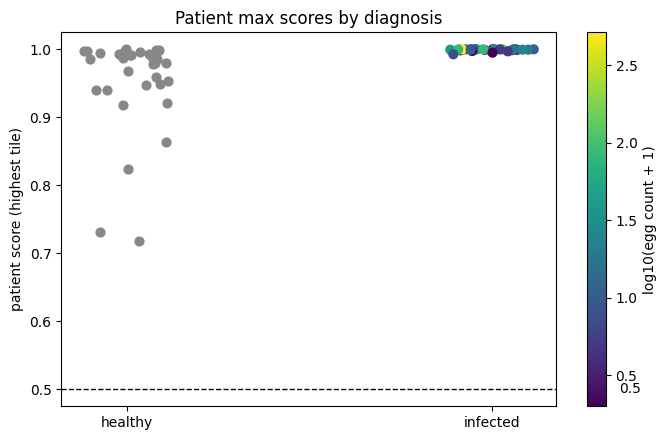

healthy  max score · min 0.7178 · median 0.9854 · max 1.0000
infected max score · min 0.9927 · median 1.0000 · max 1.0000


In [8]:
import matplotlib.pyplot as plt

smax = srt[:, 0]
jit  = np.random.default_rng(1).uniform(-0.12, 0.12, 65)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(np.zeros((y == 0).sum()) + jit[y == 0], smax[y == 0],
           c="#888888", s=40, label="healthy")
sc = ax.scatter(np.ones((y == 1).sum()) + jit[y == 1], smax[y == 1],
                c=np.log10(eggs[y == 1] + 1), cmap="viridis", s=40, label="infected")
ax.set_xticks([0, 1]); ax.set_xticklabels(["healthy", "infected"])
ax.set_ylabel("patient score (highest tile)")
ax.axhline(0.5, ls="--", lw=1, c="k"); ax.text(1.35, 0.5, "0.5", va="center")
plt.colorbar(sc, label="log10(egg count + 1)")
ax.set_title("Patient max scores by diagnosis")
plt.tight_layout(); plt.savefig(WORK / "fig_patient_scores.png", dpi=150); plt.show()

print(f"healthy  max score · min {smax[y==0].min():.4f} · median {np.median(smax[y==0]):.4f} · max {smax[y==0].max():.4f}")
print(f"infected max score · min {smax[y==1].min():.4f} · median {np.median(smax[y==1]):.4f} · max {smax[y==1].max():.4f}")

### Counting confident tiles instead of taking the maximum

The maximum saturates: every infected patient scores above 0.99, but so do
about half the healthy ones, because among 1,404 tiles a healthy sample
almost always contains one object the detector is confidently wrong about.
A single tile cannot distinguish a confident false alarm from a real egg.

The count of confident tiles can. Below, each patient is summarised by how
many of their tiles exceed a threshold, at several thresholds, and each count
is tested as a patient score. If infected samples carry several confident
tiles where healthy samples carry one or two, the count separates what the
maximum cannot.

In [9]:
print("tiles above threshold, per patient\n")
print(f"  {'threshold':>9s}   {'healthy median':>14s}   {'infected median':>15s}   {'AUROC':>6s}")
for t in (0.5, 0.9, 0.99, 0.999):
    cnt = (T > t).sum(1)
    print(f"  {t:>9}   {np.median(cnt[y==0]):>14.0f}   {np.median(cnt[y==1]):>15.0f}   "
          f"{roc_auc_score(y, cnt):>6.3f}")

c99 = (T > 0.99).sum(1)
print("\nat 0.99 · healthy counts :", sorted(c99[y==0]))
print("at 0.99 · infected counts:", sorted(c99[y==1]))

tiles above threshold, per patient

  threshold   healthy median   infected median    AUROC
        0.5               35                52    0.634
        0.9                5                24    0.802
       0.99                0                 8    0.908
      0.999                0                 3    0.875

at 0.99 · healthy counts : [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(9), np.int64(12)]
at 0.99 · infected counts: [np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(4), np.int64(4), np.int64(5), np.int64(6), np

## 5 · Deferral, evaluated honestly

The confident-tile count at 0.99 suggests a three-way rule: a patient with no
confident tiles is cleared automatically, one with more confident tiles than
any healthy patient is flagged automatically, and everyone in between is
deferred to a human reviewer. On all 65 patients that rule decides half
automatically with no errors, but those cut-offs were chosen by looking at
the same patients, which flatters the result.

Here the cut-offs are learned only from training patients and applied to
held-out ones, across 20 repetitions of 5-fold stratified cross-validation.
In each fold, the lower cut-off is the smallest count seen in any training
positive and the upper cut-off the largest seen in any training negative.
Reported are the share of held-out patients decided automatically, and how
often an automatic decision was wrong.

In [10]:
from sklearn.model_selection import RepeatedStratifiedKFold

cnt  = (T > 0.99).sum(1)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)

rows = []
for tr, te in rskf.split(cnt.reshape(-1, 1), y):
    lo = cnt[tr][y[tr] == 1].min()        # below this, no training positive was seen
    hi = cnt[tr][y[tr] == 0].max()        # above this, no training negative was seen
    s, yt = cnt[te], y[te]
    auto_neg, auto_pos = s < lo, s > hi
    rows.append(dict(
        n=len(te),
        auto=(auto_neg | auto_pos).sum(),
        auto_neg=auto_neg.sum(), auto_pos=auto_pos.sum(),
        missed=(auto_neg & (yt == 1)).sum(),       # infected patient wrongly cleared
        false_flag=(auto_pos & (yt == 0)).sum(),   # healthy patient wrongly flagged
        lo=lo, hi=hi))

df  = pd.DataFrame(rows)
tot = df.sum()
cov = df.auto / df.n

print(f"held-out decisions       {tot.n:,}  (65 patients × 20 repeats)")
print(f"decided automatically    {cov.mean():.1%}  ± {cov.std():.1%} per fold")
print(f"  auto-negative          {tot.auto_neg:,}   of which infected (missed):  {tot.missed}")
print(f"  auto-positive          {tot.auto_pos:,}   of which healthy (false):     {tot.false_flag}")
print(f"error rate when automatic  {(tot.missed + tot.false_flag) / tot.auto:.2%}")
print(f"\ncut-offs chosen · lower {sorted(df.lo.unique())} · upper {sorted(df.hi.unique())}")

held-out decisions       1,300  (65 patients × 20 repeats)
decided automatically    51.4%  ± 11.6% per fold
  auto-negative          400   of which infected (missed):  0
  auto-positive          268   of which healthy (false):     23
error rate when automatic  3.44%

cut-offs chosen · lower [np.int64(1)] · upper [np.int64(3), np.int64(9), np.int64(12)]


### Does confidence-based deferral beat random deferral?

The three-way rule shows deferral can work; this is the formal test the
proposal set out. In each cross-validation fold, a logistic regression on
the log confident-tile count is fitted to training patients only, giving
each held-out patient a probability of infection. Patients are then
deferred in order of least confidence first, and the error rate among the
patients still decided automatically is traced as coverage falls: the
risk–coverage curve. AURC, the area under that curve, summarises it; lower
is better.

Two references bound the result. Random deferral, which removes patients
regardless of confidence, shows what deferral achieves by chance. The oracle,
which defers exactly the patients the model gets wrong, shows the best any
confidence score could achieve. In notebook 02, with ImageNet features, the
confidence curve was indistinguishable from random.

AURC · confidence 0.0872 ± 0.0096
AURC · random     0.2143 ± 0.0130
AURC · oracle     0.0264

confidence beats random in 20 of 20 repeats
error at 50% coverage · confidence 6.1% · random 21.7%
error at full coverage (no deferral) · 21.4%


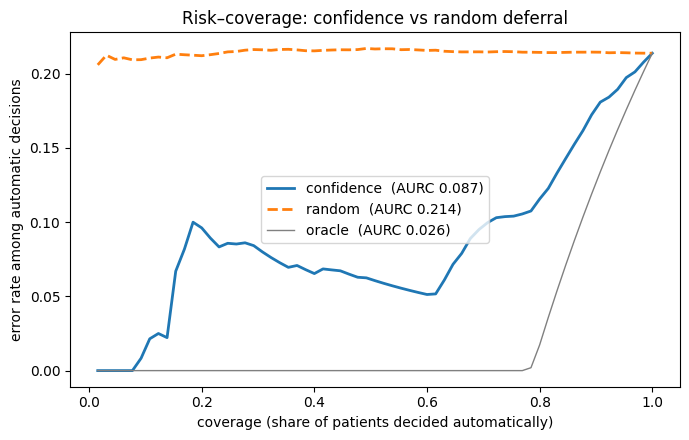

In [11]:
from sklearn.linear_model import LogisticRegression

x = np.log1p(cnt).reshape(-1, 1)
P = np.zeros((20, 65))
for i, (tr, te) in enumerate(rskf.split(x, y)):
    m = LogisticRegression(C=1e6).fit(x[tr], y[tr])
    P[i // 5, te] = m.predict_proba(x[te])[:, 1]

def curve(err, conf, rng):
    order = np.lexsort((rng.random(len(err)), -conf))   # most confident first, ties broken randomly
    e = err[order]
    return np.cumsum(e) / np.arange(1, len(e) + 1)       # risk at each coverage level

rng = np.random.default_rng(0)
cov = np.arange(1, 66) / 65
R_conf, R_rand, R_orac = [], [], []
for r in range(20):
    p    = P[r]
    err  = ((p > 0.5).astype(int) != y).astype(float)
    conf = np.abs(p - 0.5)
    R_conf.append(np.mean([curve(err, conf, rng) for _ in range(20)], axis=0))
    R_rand.append(np.mean([curve(err, rng.random(65), rng) for _ in range(50)], axis=0))
    R_orac.append(curve(err, -err, rng))

R_conf, R_rand, R_orac = map(np.array, (R_conf, R_rand, R_orac))
a_conf, a_rand, a_orac = R_conf.mean(1), R_rand.mean(1), R_orac.mean(1)

print(f"AURC · confidence {a_conf.mean():.4f} ± {a_conf.std():.4f}")
print(f"AURC · random     {a_rand.mean():.4f} ± {a_rand.std():.4f}")
print(f"AURC · oracle     {a_orac.mean():.4f}")
print(f"\nconfidence beats random in {(a_conf < a_rand).sum()} of 20 repeats")
i50 = 32

print(f"error at 50% coverage · confidence {R_conf[:, i50].mean():.1%} · random {R_rand[:, i50].mean():.1%}")
print(f"error at full coverage (no deferral) · {R_conf[:, -1].mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cov, R_conf.mean(0), lw=2,  label=f"confidence  (AURC {a_conf.mean():.3f})")
ax.plot(cov, R_rand.mean(0), lw=2, ls="--", label=f"random  (AURC {a_rand.mean():.3f})")
ax.plot(cov, R_orac.mean(0), lw=1, c="grey", label=f"oracle  (AURC {a_orac.mean():.3f})")
ax.set_xlabel("coverage (share of patients decided automatically)")
ax.set_ylabel("error rate among automatic decisions")
ax.set_title("Risk–coverage: confidence vs random deferral")
ax.legend(); plt.tight_layout()
plt.savefig(WORK / "fig_risk_coverage.png", dpi=150); plt.show()

### What the hard cases look like

The risk–coverage curve shows a few confident errors: healthy patients whose
samples contain several tiles the detector scores above 0.99. Below, the six
highest-scoring tiles for the three healthy patients with the most confident
tiles, alongside the three infected patients with the fewest. These six
patients sit in the overlap zone where an automatic decision is unreliable,
and the tiles shown are what a reviewer would be asked to judge.

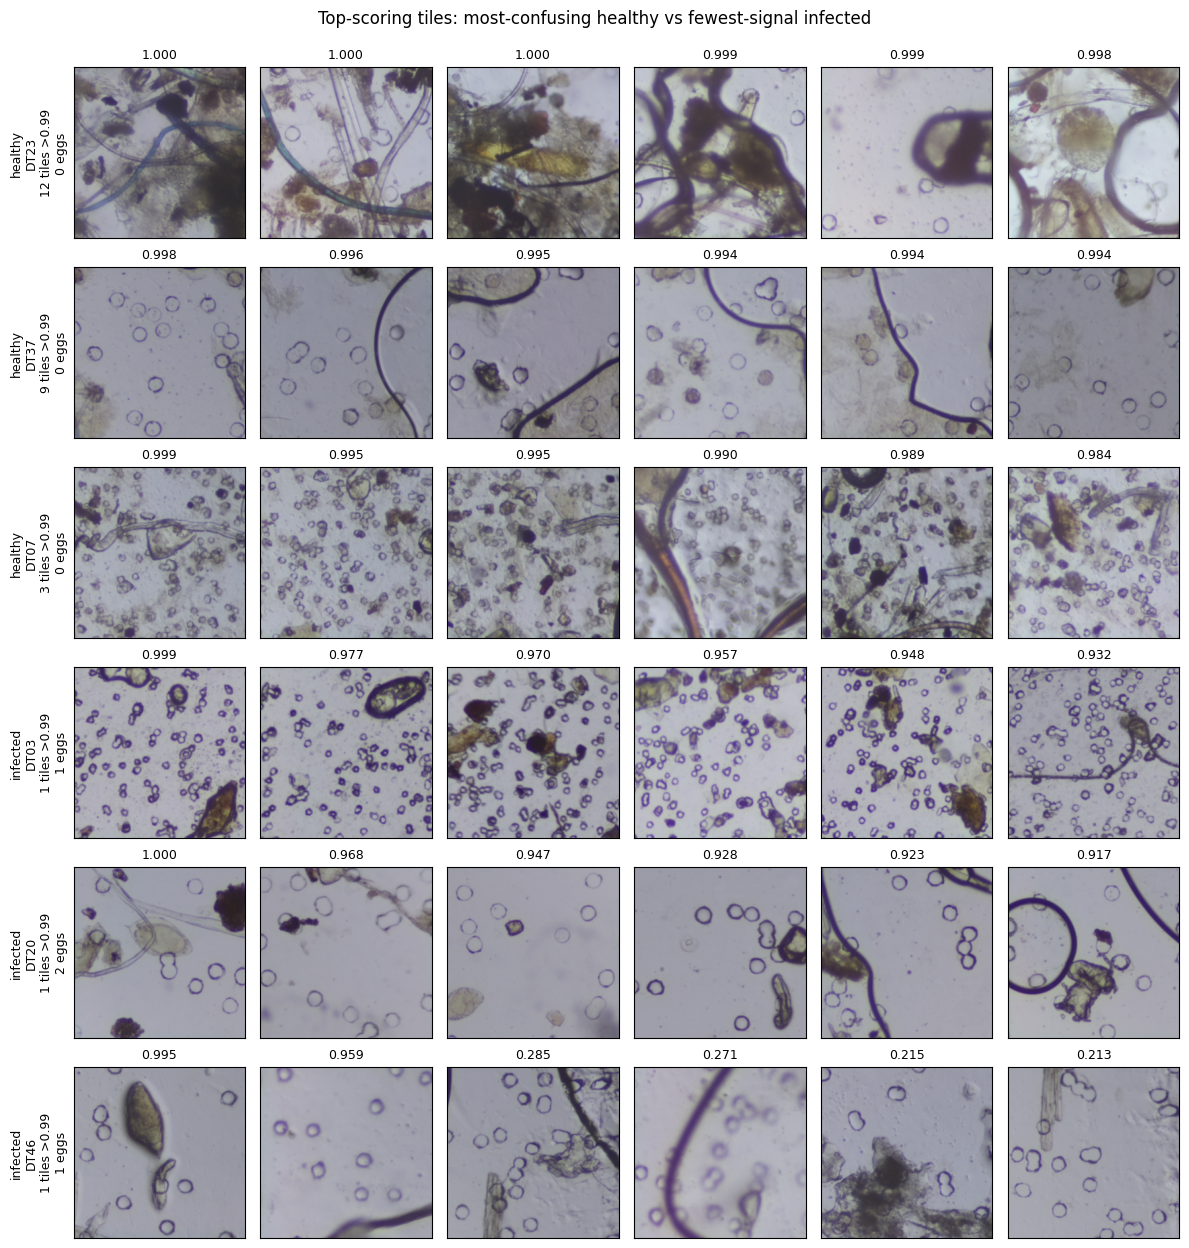

In [12]:
def get_tile(i, flat):
    f, t = divmod(int(flat), 12)
    name = next(n for n in IMGS
                if pathlib.PurePosixPath(n).parent.name == SAMPLES[i]
                and pathlib.PurePosixPath(n).name == FRAMES[i, f])
    return tiles_of(zf.read(name))[t]

healthy  = [i for i in np.argsort(-cnt) if y[i] == 0][:3]
infected = [i for i in np.argsort(cnt, kind="stable") if y[i] == 1][:3]
rows     = [(i, "healthy") for i in healthy] + [(i, "infected") for i in infected]

fig, axes = plt.subplots(6, 6, figsize=(12, 12.5))
for r, (i, lab) in enumerate(rows):
    top = np.argsort(-T[i])[:6]
    for c, flat in enumerate(top):
        ax = axes[r, c]
        ax.imshow(get_tile(i, flat)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{T[i, flat]:.3f}", fontsize=9)
    axes[r, 0].set_ylabel(f"{lab}\n{SAMPLES[i]}\n{cnt[i]} tiles >0.99\n{eggs[i]} eggs", fontsize=9)
plt.suptitle("Top-scoring tiles: most-confusing healthy vs fewest-signal infected", y=0.995)
plt.tight_layout(); plt.savefig(WORK / "fig_hard_cases.png", dpi=130); plt.show()

### Reloading the saved scores

The tile scores, labels and frame names were saved to `patient_scores.npz` in
section 4. If this session has been restarted, they are reloaded from the
notebook's committed output instead of re-downloading and re-scoring the
images. In a full run the scores are already in memory, and this cell does
nothing.

In [13]:
# checking to make sure that the 04_rescore loads.
import glob
import numpy as np

if "S" not in globals():
    path = glob.glob("/kaggle/input/**/patient_scores.npz", recursive=True)[0]
    z = np.load(path)
    S, y, eggs = z["S"], z["y"], z["eggs"]
    SAMPLES, FRAMES = list(z["samples"]), z["frames"]
    print(f"reloaded from {path}")
    print(f"S {S.shape} · {y.sum()} positive / {(1 - y).sum()} negative")
else:
    print("scores already in memory, nothing to reload")

scores already in memory, nothing to reload


In [14]:
import numpy as np
from sklearn.model_selection import RepeatedStratifiedKFold

# rebuilt here so this section depends only on the scores S and labels y
T      = S.reshape(65, -1)
smax   = T.max(1)
anyhit = (T > 0.5).any(1)
rskf   = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)

THRS = (0.9, 0.95, 0.99, 0.995, 0.999)
C    = {t: (T > t).sum(1) for t in THRS}

def best_cut(s, yy):
    """Threshold on training scores that maximises balanced accuracy."""
    best = (-1.0, None)
    for c in np.unique(s):
        p = s >= c
        bacc = (p[yy == 1].mean() + (~p[yy == 0]).mean()) / 2
        if bacc > best[0]:
            best = (bacc, c)
    return best

NAMES = ["any-detection (tile > 0.5)", "max score, single threshold",
         "count, single threshold", "random deferral", "triage (ours)",
         "full human review"]
acc = {k: dict(tp=0., fn=0., tn=0., fp=0., rev=0., n=0.) for k in NAMES}

def add(name, pred, yt, reviewed, w=1.0):
    a = acc[name]
    a["tp"] += w * (pred & (yt == 1)).sum();  a["fn"] += w * (~pred & (yt == 1)).sum()
    a["tn"] += w * (~pred & (yt == 0)).sum(); a["fp"] += w * (pred & (yt == 0)).sum()
    a["rev"] += w * reviewed;                 a["n"]  += w * len(yt)

rng = np.random.default_rng(0)

for tr, te in rskf.split(T[:, :1], y):
    yt = y[te]

    # 1 · any-detection: nothing learned, nobody reviewed
    add(NAMES[0], anyhit[te], yt, 0)

    # 2 · single threshold on the max score
    _, c = best_cut(smax[tr], y[tr])
    add(NAMES[1], smax[te] >= c, yt, 0)

    # 3 · single threshold on the count, confident-tile threshold also learned
    _, c, t = max((best_cut(C[t][tr], y[tr]) + (t,) for t in THRS), key=lambda z: z[0])
    pred3 = C[t][te] >= c
    add(NAMES[2], pred3, yt, 0)

    # 5 · triage: threshold chosen to automate the most training patients without error
    best = None
    for t in THRS:
        ctr = C[t][tr]
        lo, hi = ctr[y[tr] == 1].min(), ctr[y[tr] == 0].max()
        cov_tr = ((ctr < lo) | (ctr > hi)).mean()
        if best is None or cov_tr > best[0]:
            best = (cov_tr, t, lo, hi)
    _, t, lo, hi = best
    s = C[t][te]
    auto_pos, deferred = s > hi, ~((s < lo) | (s > hi))
    add(NAMES[4], auto_pos | (deferred & (yt == 1)), yt, deferred.sum())

    # 4 · random deferral: same number reviewed, chosen at random; the rest decided by system 3
    k = deferred.sum()
    for _ in range(20):
        d = np.zeros(len(te), bool)
        d[rng.choice(len(te), k, replace=False)] = True
        add(NAMES[3], np.where(d, yt == 1, pred3), yt, k, w=1/20)

    # 6 · full human review
    add(NAMES[5], yt == 1, yt, len(te))

print(f"{'system':30s} {'sensitivity':>12s} {'specificity':>12s} {'human review':>13s}")
for k, a in acc.items():
    print(f"{k:30s} {a['tp']/(a['tp']+a['fn']):>12.1%} {a['tn']/(a['tn']+a['fp']):>12.1%} "
          f"{a['rev']/a['n']:>13.1%}")

system                          sensitivity  specificity  human review
any-detection (tile > 0.5)           100.0%         0.0%          0.0%
max score, single threshold           85.6%        83.6%          0.0%
count, single threshold               79.4%        86.7%          0.0%
random deferral                       88.8%        93.3%         45.8%
triage (ours)                         96.9%        96.7%         45.8%
full human review                    100.0%       100.0%        100.0%


### Where the missed infections come from

Under nested selection, the triage rule cleared a small number of infected
patients that the fixed 0.99 threshold had not. Below, for every fold, the
threshold the training patients chose, and the held-out infected patients that
were cleared, with their egg counts. This shows whether the misses come from a
particular threshold choice or from particular patients.

In [15]:
import collections

chosen, misses = collections.Counter(), collections.Counter()
miss_by_t = collections.Counter()

for tr, te in rskf.split(T[:, :1], y):
    best = None
    for t in THRS:
        ctr = C[t][tr]
        lo, hi = ctr[y[tr] == 1].min(), ctr[y[tr] == 0].max()
        cov_tr = ((ctr < lo) | (ctr > hi)).mean()
        if best is None or cov_tr > best[0]:
            best = (cov_tr, t, lo, hi)
    _, t, lo, hi = best
    chosen[t] += 1
    for j in te[(C[t][te] < lo) & (y[te] == 1)]:
        misses[SAMPLES[j]] += 1
        miss_by_t[t] += 1

print("threshold chosen (folds of 100):", dict(sorted(chosen.items())))
print("missed infections by threshold :", dict(sorted(miss_by_t.items())))
print("\nmissed patients (times cleared out of 20 repeats):")
for sid, k in misses.most_common():
    i = SAMPLES.index(sid)
    print(f"  {sid}  ·  {eggs[i]} eggs  ·  missed {k}×  ·  counts "
          + "  ".join(f"{t}:{C[t][i]}" for t in THRS))

threshold chosen (folds of 100): {0.99: 80, 0.995: 20}
missed infections by threshold : {0.995: 20}

missed patients (times cleared out of 20 repeats):
  DT40  ·  7 eggs  ·  missed 20×  ·  counts 0.9:8  0.95:4  0.99:2  0.995:0  0.999:0


### Extra analysis: a safety margin on the clearing rule

Under nested selection, one infected patient (DT40, 7 eggs) was cleared in the
folds where it was held out, because the training patients chose a stricter
confident-tile threshold that DT40's eggs did not reach. This variant was
designed after that failure was observed, so it is reported as an extra
analysis, not as the main result.

The variant adds a safety margin: a confident-tile threshold may be chosen only
if every infected training patient has at least two confident tiles at that
threshold, leaving room for a held-out patient fainter than any seen in
training. A patient is cleared automatically only with zero confident tiles.
The question is how much additional human review the margin costs.

In [16]:
MARGIN = 2
res    = dict(tp=0., fn=0., tn=0., fp=0., rev=0., n=0.)
picked = collections.Counter()
missed = collections.Counter()

for tr, te in rskf.split(T[:, :1], y):
    best = None
    for t in THRS:
        ctr = C[t][tr]
        if ctr[y[tr] == 1].min() < MARGIN:          # unsafe: a training positive has fewer than 2
            continue
        hi = ctr[y[tr] == 0].max()
        cov_tr = ((ctr == 0) | (ctr > hi)).mean()
        if best is None or cov_tr > best[0]:
            best = (cov_tr, t, hi)

    if best is None:                                 # no safe threshold: clear nobody automatically
        t, allow_neg = THRS[0], False
        hi = C[t][tr][y[tr] == 0].max()
    else:
        _, t, hi = best
        allow_neg = True
    picked[t] += 1

    s, yt    = C[t][te], y[te]
    auto_neg = allow_neg & (s == 0)
    auto_pos = s > hi
    deferred = ~(auto_neg | auto_pos)
    pred     = auto_pos | (deferred & (yt == 1))

    res["tp"] += (pred & (yt == 1)).sum();  res["fn"] += (~pred & (yt == 1)).sum()
    res["tn"] += (~pred & (yt == 0)).sum(); res["fp"] += (pred & (yt == 0)).sum()

    res["rev"] += deferred.sum();           res["n"]  += len(te)
    for j in te[auto_neg & (yt == 1)]:
        missed[SAMPLES[j]] += 1

def row(name, a):
    print(f"{name:30s} {a['tp']/(a['tp']+a['fn']):>12.1%} {a['tn']/(a['tn']+a['fp']):>12.1%} "
          f"{a['rev']/a['n']:>13.1%}")

print("threshold chosen (folds of 100):", dict(sorted(picked.items())))
print("missed infected patients       :", dict(missed) if missed else "none\n")
print(f"{'system':30s} {'sensitivity':>12s} {'specificity':>12s} {'human review':>13s}")
row("triage (ours)", acc["triage (ours)"])
row("triage + safety margin", res)
row("full human review", acc["full human review"])

threshold chosen (folds of 100): {0.95: 100}
missed infected patients       : none

system                          sensitivity  specificity  human review
triage (ours)                         96.9%        96.7%         45.8%
triage + safety margin               100.0%        96.5%         72.1%
full human review                    100.0%       100.0%        100.0%


### Deferral vs random, with nested threshold selection

The risk–coverage comparison in section 5 used the confident-tile threshold of
0.99, chosen by looking at all 65 patients. Here it is repeated with the
threshold chosen inside each fold by the training patients, using the same rule
as the triage system, so the comparison between confidence-based and random
deferral is free of that choice.

AURC · confidence 0.0946 ± 0.0131
AURC · random     0.2065 ± 0.0164
AURC · oracle     0.0244

confidence beats random in 20 of 20 repeats
error at 50% coverage · confidence 8.0% · random 20.9%


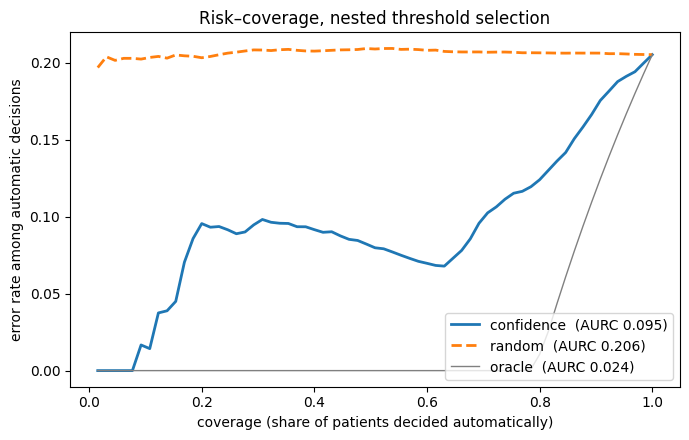

In [17]:
import pathlib; WORK = pathlib.Path("/kaggle/working")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

P2 = np.zeros((20, 65))
for i, (tr, te) in enumerate(rskf.split(T[:, :1], y)):
    best = None
    for t in THRS:
        ctr = C[t][tr]
        lo, hi = ctr[y[tr] == 1].min(), ctr[y[tr] == 0].max()
        cov_tr = ((ctr < lo) | (ctr > hi)).mean()
        if best is None or cov_tr > best[0]:
            best = (cov_tr, t)
    xt = np.log1p(C[best[1]]).reshape(-1, 1)
    m  = LogisticRegression(C=1e6).fit(xt[tr], y[tr])
    P2[i // 5, te] = m.predict_proba(xt[te])[:, 1]

def curve(err, conf, rng):
    order = np.lexsort((rng.random(len(err)), -conf))
    e = err[order]
    return np.cumsum(e) / np.arange(1, len(e) + 1)

rng = np.random.default_rng(0)
cov = np.arange(1, 66) / 65
Rc, Rr, Ro = [], [], []
for r in range(20):
    err  = ((P2[r] > 0.5).astype(int) != y).astype(float)
    conf = np.abs(P2[r] - 0.5)
    Rc.append(np.mean([curve(err, conf, rng) for _ in range(20)], axis=0))
    Rr.append(np.mean([curve(err, rng.random(65), rng) for _ in range(50)], axis=0))
    Ro.append(curve(err, -err, rng))
Rc, Rr, Ro = map(np.array, (Rc, Rr, Ro))
ac, ar, ao = Rc.mean(1), Rr.mean(1), Ro.mean(1)

print(f"AURC · confidence {ac.mean():.4f} ± {ac.std():.4f}")
print(f"AURC · random     {ar.mean():.4f} ± {ar.std():.4f}")
print(f"AURC · oracle     {ao.mean():.4f}")
print(f"\nconfidence beats random in {(ac < ar).sum()} of 20 repeats")
print(f"error at 50% coverage · confidence {Rc[:, 32].mean():.1%} · random {Rr[:, 32].mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cov, Rc.mean(0), lw=2, label=f"confidence  (AURC {ac.mean():.3f})")
ax.plot(cov, Rr.mean(0), lw=2, ls="--", label=f"random  (AURC {ar.mean():.3f})")
ax.plot(cov, Ro.mean(0), lw=1, c="grey", label=f"oracle  (AURC {ao.mean():.3f})")
ax.set_xlabel("coverage (share of patients decided automatically)")
ax.set_ylabel("error rate among automatic decisions")
ax.set_title("Risk–coverage, nested threshold selection")
ax.legend(); plt.tight_layout()
plt.savefig(WORK / "fig_risk_coverage_nested.png", dpi=150); plt.show()

### Confidence intervals

With 65 patients, every headline number is an estimate. Below, 95% confidence
intervals for sensitivity, specificity and the share of samples sent to a
reviewer, for the main triage rule and the safety-margin variant. Each patient's
outcome is averaged across the 20 cross-validation repeats, and exact
Clopper–Pearson intervals are computed over patients: 32 infected for
sensitivity, 33 healthy for specificity, all 65 for review share. The intervals
reflect uncertainty from the small cohort, the dominant source of uncertainty
here; for the deferral comparison, the spread across repeats and the 20-of-20
result are reported above.

In [18]:
from scipy.stats import beta

def triage_runs(margin=None):
    """Per-patient share of repeats decided correctly, and share deferred."""
    correct  = np.zeros((20, 65))
    deferred = np.zeros((20, 65))
    for i, (tr, te) in enumerate(rskf.split(T[:, :1], y)):
        r, best = i // 5, None
        for t in THRS:
            ctr  = C[t][tr]
            pmin = ctr[y[tr] == 1].min()
            hi   = ctr[y[tr] == 0].max()
            if margin is None:
                lo = pmin
            else:
                if pmin < margin:
                    continue
                lo = 1                                  # clear only patients with zero confident tiles
            cov_tr = ((ctr < lo) | (ctr > hi)).mean()
            if best is None or cov_tr > best[0]:
                best = (cov_tr, t, lo, hi)
        if best is None:
            t, lo = THRS[0], 0
            hi = C[t][tr][y[tr] == 0].max()
        else:
            _, t, lo, hi = best
        s, yt = C[t][te], y[te]
        d     = ~((s < lo) | (s > hi))
        pred  = (s > hi) | (d & (yt == 1))
        correct[r, te]  = pred == (yt == 1)
        deferred[r, te] = d
    return correct.mean(0), deferred.mean(0)


def cp(k, n, a=0.05):
    lo = 0.0 if k <= 0 else beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k >= n else beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

def report(name, correct, deferred):
    pos, neg = y == 1, y == 0
    rows = [("sensitivity", correct[pos].sum(), pos.sum()),
            ("specificity", correct[neg].sum(), neg.sum()),
            ("human review", deferred.sum(), 65)]
    print(name)
    for label, k, n in rows:
        lo, hi = cp(k, n)
        print(f"  {label:13s} {k/n:6.1%}   95% CI {lo:6.1%} – {hi:6.1%}")
    print()

report("triage (ours)", *triage_runs())
report("triage + safety margin", *triage_runs(margin=2))

triage (ours)
  sensitivity    96.9%   95% CI  83.8% –  99.9%
  specificity    96.7%   95% CI  83.8% –  99.9%
  human review   45.8%   95% CI  33.4% –  58.7%

triage + safety margin
  sensitivity   100.0%   95% CI  89.1% – 100.0%
  specificity    96.5%   95% CI  83.5% –  99.9%
  human review   72.1%   95% CI  59.6% –  82.5%



## 8 · Summary

- **The detector works at patient level.** Max-pooled tile scores separate
  infected from healthy patients with AUROC 0.950; averaging dilutes the signal
  (0.616), because egg tiles are rare. The detector was trained on a separate
  dataset and never saw these 65 patients.
- **The any-detection failure reproduces.** Calling a patient positive if any
  tile exceeds 0.5 gives 100% sensitivity and 0% specificity: every healthy
  sample contains at least one confident false alarm among 1,404 tiles.
- **Fully automatic alternatives fall short.** A single learned threshold on the
  maximum score or the confident-tile count reaches 84–87% specificity but
  misses 15–21% of infected patients.
- **Triage, with every choice made inside cross-validation:** 96.9% sensitivity
  (95% CI 83.8–99.9%) and 96.7% specificity (83.8–99.9%), with 45.8% of samples
  sent to a reviewer (33.4–58.7%). Random deferral of the same number of
  samples reaches only 88.8% and 93.3%.
- **The one missed infection is explained.** DT40 (7 eggs) was cleared only in
  folds where it was held out and the training patients chose a stricter
  threshold its eggs did not reach.
- **Extra analysis, designed after that failure:** a safety margin on the
  threshold choice prevents the miss, giving 100% sensitivity (95% CI lower
  bound 89.1%) and 96.5% specificity, at the cost of 72.1% of samples reviewed.
- **Confidence-based deferral beats random deferral** in 20 of 20 repeats (AURC
  0.095 vs 0.206; error at 50% coverage 8.0% vs 20.9%). In notebook 02, with
  frozen ImageNet features, the two were indistinguishable.
- **Hard cases are explainable.** Confident false alarms concentrate in debris-
  and fibre-heavy samples, and the hardest infected patients carry a single
  egg; by count alone they cannot be told apart, which is the case for
  deferring them to a reviewer.
- **Limitations.** 65 patients from a single dataset, so all estimates carry
  wide intervals; the cut-offs depend on the most extreme patients in training;
  the triage rule has not been validated on an independent cohort.

Sections 4–5 are the exploratory pass, where the 0.99 threshold was chosen on
all 65 patients; the figures reported above come from sections 7 onward, where
every choice is made inside cross-validation.